In [2]:
import numpy as np
import tensorflow as tf
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

In [3]:
dataset = pd.read_csv('./dataset/weatherHistory.csv')
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Summary                   96453 non-null  object 
 2   Precip Type               95936 non-null  object 
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  object 
dtypes: float64(8), object(4)
memory usage: 8.8+ MB


In [4]:
# feature selection
dataset = dataset.drop(["Formatted Date", "Summary", "Precip Type", "Loud Cover", "Daily Summary"], axis=1)
dataset = dataset.dropna()

In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Temperature (C)           96453 non-null  float64
 1   Apparent Temperature (C)  96453 non-null  float64
 2   Humidity                  96453 non-null  float64
 3   Wind Speed (km/h)         96453 non-null  float64
 4   Wind Bearing (degrees)    96453 non-null  float64
 5   Visibility (km)           96453 non-null  float64
 6   Pressure (millibars)      96453 non-null  float64
dtypes: float64(7)
memory usage: 5.2 MB


In [6]:
non_target_features = dataset.drop(["Humidity"], axis=1)
target_features = dataset["Humidity"]

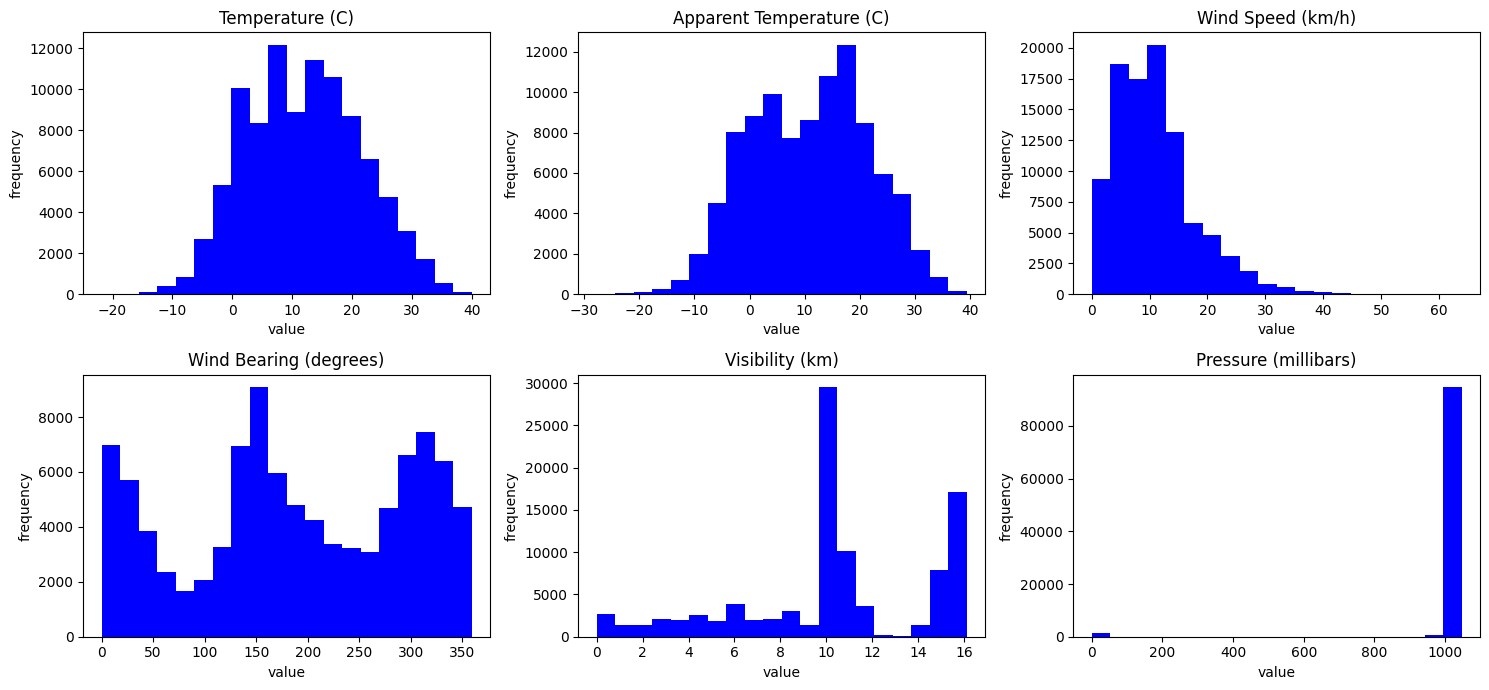

In [7]:
plt.figure(figsize=(15,7))
for i, col in enumerate(non_target_features):
    plt.subplot(2, 3, i+1)
    plt.hist(non_target_features[col], color="blue", bins=20)
    plt.title(col)
    plt.xlabel('value')
    plt.ylabel('frequency')
    plt.tight_layout()

In [8]:
# split data
# 80% train : 10% val : 10% test

x_train, x_temp, y_train, y_temp = train_test_split(non_target_features, target_features, test_size=0.2, random_state=67)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, test_size=0.5, random_state=89)

In [9]:
# standarisasi data
scale = StandardScaler()

x_train = scale.fit_transform(x_train)
x_test = scale.transform(x_test)
x_val = scale.transform(x_val)

In [10]:
# buat model dan arsitektur aja
model = Sequential([
    Dense(32, activation='relu', input_dim=x_train.shape[1]),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='linear'),
])

model.compile(optimizer="adam", loss='mae', metrics=['mean_squared_error'])

In [11]:
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        print(gpu.name)
else:
    print("fuck you")


/physical_device:GPU:0


In [12]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=50,
    batch_size=32
)

Epoch 1/50
2412/2412 [==============================] - 8s 2ms/step - loss: 0.1046 - mean_squared_error: 0.0214 - val_loss: 0.0907 - val_mean_squared_error: 0.0148
Epoch 2/50
2412/2412 [==============================] - 12s 5ms/step - loss: 0.0885 - mean_squared_error: 0.0142 - val_loss: 0.0909 - val_mean_squared_error: 0.0142
Epoch 3/50
2412/2412 [==============================] - 13s 5ms/step - loss: 0.0861 - mean_squared_error: 0.0136 - val_loss: 0.0877 - val_mean_squared_error: 0.0136
Epoch 4/50
2412/2412 [==============================] - 13s 5ms/step - loss: 0.0845 - mean_squared_error: 0.0132 - val_loss: 0.0844 - val_mean_squared_error: 0.0135
Epoch 5/50
2412/2412 [==============================] - 13s 5ms/step - loss: 0.0836 - mean_squared_error: 0.0131 - val_loss: 0.0843 - val_mean_squared_error: 0.0130
Epoch 6/50
2412/2412 [==============================] - 13s 5ms/step - loss: 0.0830 - mean_squared_error: 0.0129 - val_loss: 0.0831 - val_mean_squared_error: 0.0129
Epoch 7/50


In [13]:
loss, mse = model.evaluate(x_test, y_test)
print(loss)
print(mse)

302/302 [==============================] - 0s 1ms/step - loss: 0.0790 - mean_squared_error: 0.0125
0.07904475927352905
0.012454350478947163


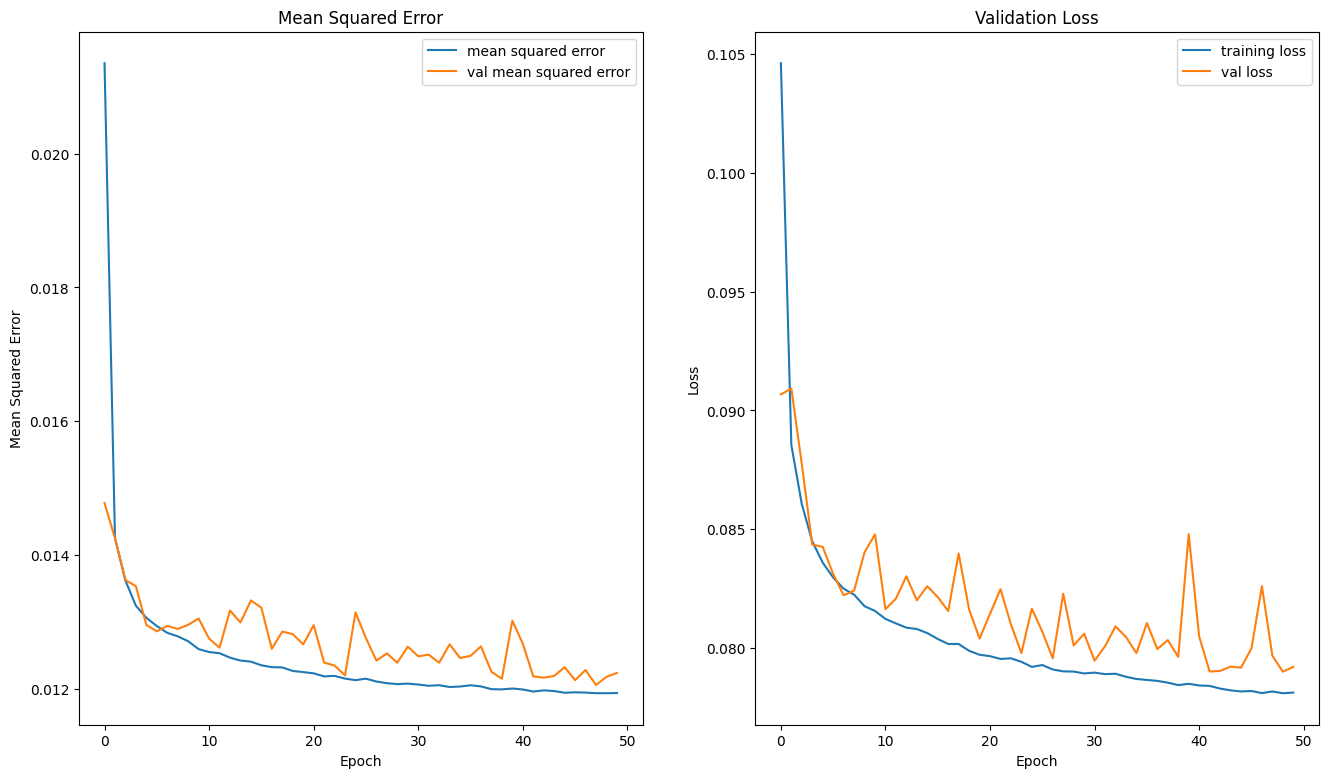

In [17]:
# visualisasi hasil training

plt.figure(figsize=(16,9))
plt.subplot(1,2,1)
plt.plot(history.history['mean_squared_error'], label='mean squared error')
plt.plot(history.history['val_mean_squared_error'] , label='val mean squared error')
plt.title('Mean Squared Error')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'] , label='val loss')
plt.title('Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [22]:
# prediction
prediction_values = []
actual_values = []

predictions = model.predict(x_test[:5])

for value in predictions:
    prediction_values.append(value[0])
    
actual = y_test[:5].values
for value in actual:
    actual_values.append(value)
    
    
print("Prediction           Actual")
print("===========================")
for (predicted, actual) in zip(prediction_values, actual_values):
    print(f"{predicted}     {actual}")


1/1 [==============================] - 0s 15ms/step
Prediction           Actual
0.7184841632843018     0.77
0.9025837779045105     0.68
0.9855566024780273     1.0
0.8532249927520752     0.93
0.7044614553451538     0.76
